# 04 学習済みCNNによる画像分類

ResNet18で前処理→予測→上位5クラスを実行し、画像分類の範囲と限界を考えます。

必要なライブラリ：PyTorch、torchvision、Pillow、Matplotlib

[Google Colabで開く](https://colab.research.google.com/github/m-riho/information-science-interactive-lab/blob/main/public/notebooks/session07/04_image_classification.ipynb)

Colabリンクは、このファイルを既存の公開リポジトリへ反映した後に利用できます。

Python 3.12以降を想定し、作者の実行検証はPython 3.13.5で行います。
依存ライブラリは同じフォルダのrequirements.txtを参照してください。
ローカルでは新しい仮想環境で `python -m pip install -r requirements.txt` を実行します。
Colabではランタイム標準ライブラリでも試せますが、版の違いで結果は変わる場合があります。必要ならrequirements.txtに合わせてインストールし、ランタイムを再起動してください。
実行は「ランタイム／カーネル → すべて実行」。保存済みの出力は作者の実測例です。

## 概要・画像・モデル

torchvisionのResNet18とIMAGENET1K_V1重みを使います。初回は約45MBの重みをdownload.pytorch.orgから取得し、PyTorchのキャッシュに保存します。以降はキャッシュがあれば再ダウンロードしません。入力はNASA撮影のEileen Collinsの写真（Public Domain、scikit-image配布）です。

オフラインでは事前に重みをキャッシュし、同梱assets/astronaut.pngを配置します。Notebookだけ取得した場合、画像を公式scikit-imageリポジトリからダウンロードします。ネットワークがなく必要なファイルもない場合は、推論できないことを表示し、未学習重みの予測で代用しません。

Python: 3.13.5 torch: 2.13.0 torchvision: 0.28.0 Pillow: 12.2.0
入力画像SHA256: 88431cd9653ccd539741b555fb0a46b61558b301d4110412b5bc28b5e3ea6cb5


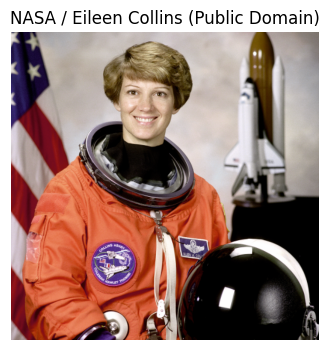

In [1]:
import sys
from pathlib import Path
from urllib.request import urlopen
import hashlib
from io import BytesIO
import matplotlib.pyplot as plt
from PIL import Image
import PIL
import torch, torchvision
from torchvision.models import resnet18, ResNet18_Weights
torch.manual_seed(7)
torch.set_num_threads(2)
print("Python:",sys.version.split()[0],"torch:",torch.__version__,
      "torchvision:",torchvision.__version__,"Pillow:",PIL.__version__)
image = None
path = Path("assets/astronaut.png")
image_url = "https://raw.githubusercontent.com/scikit-image/scikit-image/v0.25.2/skimage/data/astronaut.png"
try:
    content = path.read_bytes() if path.exists() else urlopen(image_url, timeout=20).read()
    image = Image.open(BytesIO(content)).convert("RGB")
    print("入力画像SHA256:", hashlib.sha256(content).hexdigest())
    plt.figure(figsize=(4,4)); plt.imshow(image); plt.axis("off")
    plt.title("NASA / Eileen Collins (Public Domain)")
    plt.show()
except (OSError, ValueError) as error:
    print("画像が読めません。assets/astronaut.pngを配置して再実行してください。", type(error).__name__)

写真の人物の身元を予測する実験ではありません。クラスはImageNetの1000分類であり、画像の一般的な意味をすべて説明するものではありません。画像の出典とライセンスは末尾に記載しています。

## 重みの取得と前処理

学習済み重みに対応する公式transformsを使い、RGB→リサイズ→中央224×224切出し→0〜1のテンソル→ImageNet平均・標準偏差で正規化します。

学習済み重み: ResNet18_Weights.IMAGENET1K_V1
前処理後の形: (1, 3, 224, 224)


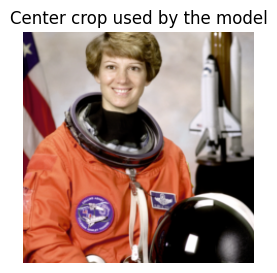

In [2]:
weights = ResNet18_Weights.IMAGENET1K_V1
model = None
batch = None
try:
    model = resnet18(weights=weights).eval()
    print("学習済み重み:", weights)
except (OSError, RuntimeError, ValueError) as error:
    print("学習済み重みを取得できません。オンラインで一度実行するか、重みをPyTorchキャッシュへ配置してください。",
          type(error).__name__)
if image is not None and model is not None:
    batch = weights.transforms()(image).unsqueeze(0)
    assert batch.shape == (1,3,224,224)
    print("前処理後の形:", tuple(batch.shape))
    # 表示用に正規化だけを元へ戻す。切出し後の画像を示す。
    shown = batch[0] * torch.tensor([.229,.224,.225])[:,None,None] + torch.tensor([.485,.456,.406])[:,None,None]
    plt.figure(figsize=(3,3)); plt.imshow(shown.permute(1,2,0).clamp(0,1))
    plt.title("Center crop used by the model"); plt.axis("off"); plt.show()

中央切出しによって画像の一部は使われません。入力の扱いも結果に影響します。eval()は推論時の振る舞いを指定する操作で、学習済み重みを新しく学習し直す操作ではありません。

## 推論と上位5クラス

CPUで学習済みモデルを実行し、Softmaxの上位5出力を表示します。ImageNetのクラス名は公式の英語表記を使います。

reel: 11.30%
stethoscope: 10.88%
drumstick: 3.18%
gasmask: 3.12%
football helmet: 3.11%


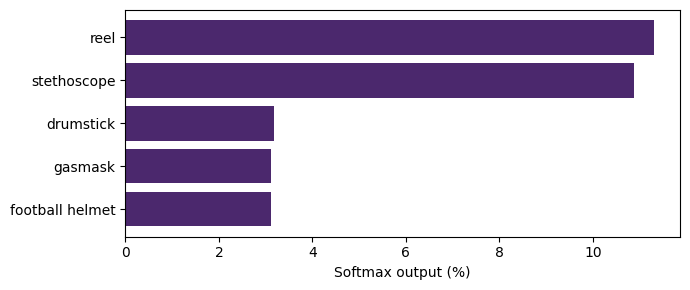

In [3]:
probabilities = None
if batch is not None and model is not None:
    with torch.inference_mode():
        probabilities = model(batch).softmax(dim=1)[0]
    values, indices = probabilities.topk(5)
    assert abs(float(probabilities.sum())-1) < 1e-5
    labels = [weights.meta["categories"][int(i)] for i in indices]
    for label, value in zip(labels, values):
        print(f"{label}: {100*float(value):.2f}%")
    fig, ax = plt.subplots(figsize=(7,3))
    ax.barh(labels[::-1], values.flip(0).numpy()*100, color="#4b286d")
    ax.set_xlabel("Softmax output (%)")
    plt.tight_layout(); plt.show()
else:
    print("画像または学習済み重みがないため、推論をスキップしました。")

上位クラスは、モデルが1000クラスの中から選んだ候補です。Softmax値はこの画像で本当にその対象であるという保証ではありません。ImageNetの出力には人物の身元や画像の詳細な説明は含まれません。

## 条件を変える実験

同じ写真を左右反転して入力し、上位候補を比べます。別の写真を使う場合も権利を確認し、RGBに変換して同じ前処理を適用します。

In [4]:
if image is not None and model is not None:
    flipped = image.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
    with torch.inference_mode():
        altered = model(weights.transforms()(flipped).unsqueeze(0)).softmax(dim=1)[0]
    values, indices = altered.topk(5)
    print("左右反転した画像の上位5クラス")
    for i, value in zip(indices, values):
        print(weights.meta["categories"][int(i)], f"{100*float(value):.2f}%")
else:
    print("必要な入力がないため、条件変更の実験をスキップしました。")

左右反転した画像の上位5クラス
stethoscope 11.95%
lens cap 10.62%
reel 5.98%
wine bottle 5.74%
bobsled 4.04%


見た目の変更にどの程度頑健かを調べる一例です。1枚の結果からモデル全体の性能を決めつけることはできません。

## まとめ

既存の重みを読み込み、画像を前処理し、推論して候補を表示できました。このNotebookでは追加学習は行わず、学習済みモデルを利用しました。

## 参考資料

- [ResNet18の公式重みと前処理](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)
- [scikit-image astronaut画像の出典・Public Domain表記](https://scikit-image.org/docs/0.25.x/api/skimage.data.html#skimage.data.astronaut)
- [配布元の画像（v0.25.2）](https://github.com/scikit-image/scikit-image/blob/v0.25.2/skimage/data/astronaut.png)
- [NASAの原画像・Public Domain表記](https://www.dvidshub.net/image/861340/astronaut-eileen-collins)

同梱画像：NASA撮影、scikit-image収録astronaut.png、512×512、未改変。画像分類の教育用途。モデル重みはリポジトリへ同梱しません。